# Tome S3, Chapter 3: Goldbach (Python companion)

Exercises first, solutions at the end. We draw the Goldbach comet up to $10^7$ with a fast Fourier transform, compare it with the Hardy–Littlewood prediction, compute Schnirelmann densities, chase the least prime in a Goldbach partition, test Lemoine's conjecture, and look at the exponential sum $S(\alpha)$ of the circle method. We use `numpy`, `sympy` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import math
import numpy as np
import sympy
import matplotlib.pyplot as plt
N = 10**7
s = np.ones(N + 1, bool); s[:2] = False
for p in range(2, int(N**0.5) + 1):
    if s[p]: s[p*p::p] = False
primes = np.nonzero(s)[0]
C2 = 1.0
for p in sympy.primerange(3, 10**6):
    C2 *= 1 - 1 / (p - 1)**2
print(len(primes), 'primes up to 10^7, C2 =', C2)

664579 primes up to 10^7, C2 = 0.6601618605898382


## Exercises

**P3.1 (★★) The comet.** Compute $r(n)=\#\{(p,q):p+q=n\}$ for all $n\le10^7$ at once, as the square of the polynomial $\sum_p x^p$, with a fast Fourier transform. Check a few values directly, plot a sample of the comet coloured by $n \bmod 3$, and compare $r(n)$ with $\mathfrak S(n)J(n)$ (Remark 3.1) at $n=10^5,10^6,10^7$.

**P3.2 (★) Schnirelmann densities.** For $A=\{0,1\}\cup\{p+q\}$ and $B=\{0,1\}\cup\{\text{primes}\}$, compute $\min_{n\le10^7}\frac{A(n)}n$ and $\min_{n\le10^7}\frac{B(n)}n$, and where they are attained. If these were the true densities, what $h$ would Exercise 3.2 give for $A$?

**P3.3 (★) The least Goldbach prime.** For every even $4\le n\le10^7$ find the least prime $p(n)$ with $n-p(n)$ prime. List the records and compare them with $(\log n)^2$.

**P3.4 (★★) The singular series.** Check Exercise 3.7: the average of $\mathfrak S(n)$ over even $n\le x$ tends to $2$. Then sort the even $n\le10^6$ by their set of odd prime factors below $10$ and compare the mean of $r(n)/J(n)$ in each class with the predicted $2C_2\prod\frac{p-1}{p-2}$ (Exercise 3.6).

**P3.5 (★) Lemoine.** Check that every odd $n$ with $7\le n\le10^7$ is $p+2q$ with $p,q$ prime. Which $n$ have the fewest representations, relative to their size?

**P3.6 (★★) The circle method.** For $N=10^4$, compute $S(\alpha)=\sum_{p\le N}e(p\alpha)$ on a fine grid, check numerically that $\int_0^1S(\alpha)^2e(-N\alpha)\,d\alpha=r(N)$ and $\int_0^1|S|^2=\pi(N)$ (Exercise 3.8), and plot $|S(\alpha)|$. Where are the peaks?

## Solutions

### P3.1
**How to find it.** If $f=\sum_p x^p$ then $f^2=\sum_n r(n)x^n$. The FFT computes $f^2$ in $O(N\log N)$ operations; rounding to the nearest integer is safe because the values are below $10^6$ and the floating-point error is far below $\frac12$.

n=  100000  r(n)=   1620  S(n)=1.7604  S(n)J(n)=   1620.7  ratio 0.9996
n= 1000000  r(n)=  10804  S(n)=1.7604  S(n)J(n)=  10834.2  ratio 0.9972
n=10000000  r(n)=  77614  S(n)=1.7604  S(n)J(n)=  77586.4  ratio 1.0004


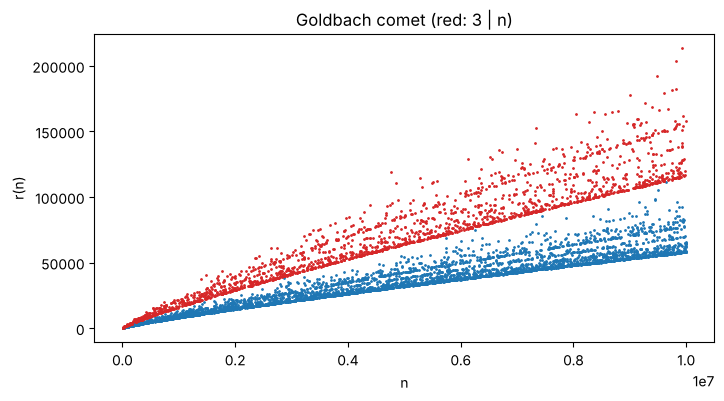

In [2]:
L = 1 << (2 * N + 2).bit_length()
F = np.fft.rfft(s.astype(np.float64), L)
r = np.rint(np.fft.irfft(F * F, L)[:N + 1]).astype(np.int64)
del F
for n in (100, 1000, 10**6):
    assert r[n] == sum(1 for p in primes[primes < n] if s[n - p])
fac = np.ones(N + 1)
for p in sympy.primerange(3, N + 1):
    fac[p::p] *= (p - 1) / (p - 2)
Sg = 2 * C2 * fac; Sg[1::2] = 0
from scipy.integrate import quad
def J(n):
    return quad(lambda t: 1 / (math.log(t) * math.log(n - t)), 2, n - 2, limit=500)[0]
for n in (10**5, 10**6, 10**7):
    print('n=%8d  r(n)=%7d  S(n)=%.4f  S(n)J(n)=%9.1f  ratio %.4f' % (n, r[n], Sg[n], Sg[n] * J(n), r[n] / (Sg[n] * J(n))))
rng = np.random.default_rng(0)
ns = rng.choice(np.arange(6, N + 1, 2), 6000, replace=False)
fig, ax = plt.subplots(figsize=(8, 4))
for res, c in ((1, 'C0'), (2, 'C0'), (0, 'C3')):
    m = ns[ns % 3 == res]
    ax.scatter(m, r[m], s=1, c=c)
ax.set_xlabel('n'); ax.set_ylabel('r(n)'); ax.set_title('Goldbach comet (red: 3 | n)'); plt.show()

The three ratios are within half a percent of $1$ (the integral is computed with `scipy.integrate.quad`; a coarse trapezoidal rule overestimates $J(n)$ by about one percent, because $\frac1{\log t}$ changes fast near $t=2$). The comet splits cleanly into the band $3\nmid n$ and the band $3\mid n$, twice as high.

### P3.2
**How to find it.** $A(n)$ is a cumulative sum of the indicator of $\{1\}\cup\{m: r(m)>0\}$.

In [3]:
inA = (r > 0); inA[1] = True; inA[0] = False
An = np.cumsum(inA)[1:]; n = np.arange(1, N + 1)
q = An / n; i = int(np.argmin(q))
print('A: min A(n)/n = %.6f at n = %d (A(n) = %d)' % (q[i], i + 1, An[i]))
inB = s.copy(); inB[1] = True
Bn = np.cumsum(inB)[1:]; qb = Bn / n; j = int(np.argmin(qb))
print('B: min B(n)/n = %.6f at n = %d' % (qb[j], j + 1))
alpha = q[i]
k = math.ceil(math.log(2) / -math.log(1 - alpha))
print('if sigma(A) were %.4f: k = %d, h = 2k = %d elements of A' % (alpha, k, 2 * k))

A: min A(n)/n = 0.333333 at n = 3 (A(n) = 1)


B: min B(n)/n = 0.066458 at n = 9999862
if sigma(A) were 0.3333: k = 2, h = 2k = 4 elements of A


Up to $10^7$ the infimum of $\frac{A(n)}n$ is $\frac13$, attained at $n=3$: neither $2$ nor $3$ is a sum of two primes. Further on, the sums of two primes are essentially all the even numbers plus the odd numbers $p+2$, so $\frac{A(n)}n$ stays a little above $\frac12$. If $\sigma(A)$ were $\frac13$, Exercise 3.2 would give $k=2$, so every integer would be a sum of $4$ elements of $A$, hence of at most $8$ primes and a few ones; Schnirelmann's real difficulty is proving any positive lower bound for all $n$, not computing it. The primes themselves have $\frac{B(n)}n\to0$, so $\sigma(B)=0$ in the limit, and on this range the minimum sits at $10^7$, where it is about $\frac1{\log n}$; that is why Schnirelmann had to add primes in pairs.

### P3.3
**How to find it.** For each even $n$, walk up the list of primes until $n-p$ is prime. Vectorised: for each small prime $p$, mark the even $n$ not yet solved for which $n-p$ is prime.

In [4]:
pn = np.zeros(N + 1, np.int64)
evens = np.arange(4, N + 1, 2)
todo = evens.copy()
for p in primes:
    ok = s[todo - p] & (todo - p >= 2)
    pn[todo[ok]] = p
    todo = todo[~ok]
    if len(todo) == 0: break
rec = []; best = 0
for n in evens:
    if pn[n] > best: best = int(pn[n]); rec.append((int(n), best))
for n, p in rec: print('%9d  p(n)=%4d  (log n)^2 = %6.1f' % (n, p, math.log(n)**2))

        4  p(n)=   2  (log n)^2 =    1.9
        6  p(n)=   3  (log n)^2 =    3.2
       12  p(n)=   5  (log n)^2 =    6.2
       30  p(n)=   7  (log n)^2 =   11.6
       98  p(n)=  19  (log n)^2 =   21.0
      220  p(n)=  23  (log n)^2 =   29.1
      308  p(n)=  31  (log n)^2 =   32.8
      556  p(n)=  47  (log n)^2 =   40.0
      992  p(n)=  73  (log n)^2 =   47.6
     2642  p(n)= 103  (log n)^2 =   62.1
     5372  p(n)= 139  (log n)^2 =   73.8
     7426  p(n)= 173  (log n)^2 =   79.4
    43532  p(n)= 211  (log n)^2 =  114.1
    54244  p(n)= 233  (log n)^2 =  118.8
    63274  p(n)= 293  (log n)^2 =  122.2
   113672  p(n)= 313  (log n)^2 =  135.5
   128168  p(n)= 331  (log n)^2 =  138.3
   194428  p(n)= 359  (log n)^2 =  148.3
   194470  p(n)= 383  (log n)^2 =  148.3
   413572  p(n)= 389  (log n)^2 =  167.3
   503222  p(n)= 523  (log n)^2 =  172.4
  1077422  p(n)= 601  (log n)^2 =  192.9
  3526958  p(n)= 727  (log n)^2 =  227.3
  3807404  p(n)= 751  (log n)^2 =  229.6


The records grow very slowly: $p(98)=19$, $p(503\,222)=523$, and the last record below $10^7$ is $p(3\,807\,404)=751$. The ratio of the records to $(\log n)^2$ creeps up, from about $1$ near $100$ to $3.3$ at the last record. Oliveira e Silva's record $p(n)=9781$ at $n\approx3.3\cdot10^{18}$ is about $5.4$ times $(\log n)^2\approx1819$. What the true growth rate is, nobody knows; it is one of the open doors of the chapter.

### P3.4
**How to find it.** The array `Sg` already holds $\mathfrak S(n)$. For the classes, use $n\bmod 3$, $n\bmod5$, $n\bmod7$.

In [5]:
for e in (3, 4, 5, 6, 7):
    x = 10**e
    print('x=10^%d  mean of S(n) over even n <= x: %.5f' % (e, Sg[2:x + 1:2].mean()))
M = 10**6
ev = np.arange(10**5, M + 1, 2)
Jv = np.array([J(int(n)) for n in ev[::50]])
Jfull = np.interp(ev, ev[::50], Jv)
base = r[ev] / Jfull
for d3 in (0, 1):
    for d5 in (0, 1):
        for d7 in (0, 1):
            m = ((ev % 3 == 0) == d3) & ((ev % 5 == 0) == d5) & ((ev % 7 == 0) == d7)
            pred = 2 * C2 * (2 if d3 else 1) * (4 / 3 if d5 else 1) * (6 / 5 if d7 else 1)
            print('3|n:%d 5|n:%d 7|n:%d  mean r/J = %.4f  2C2*prod = %.4f' % (d3, d5, d7, base[m].mean(), pred))

x=10^3  mean of S(n) over even n <= x: 1.99216
x=10^4  mean of S(n) over even n <= x: 1.99902
x=10^5  mean of S(n) over even n <= x: 1.99988
x=10^6  mean of S(n) over even n <= x: 1.99999
x=10^7  mean of S(n) over even n <= x: 2.00000


3|n:0 5|n:0 7|n:0  mean r/J = 1.3621  2C2*prod = 1.3203
3|n:0 5|n:0 7|n:1  mean r/J = 1.6344  2C2*prod = 1.5844
3|n:0 5|n:1 7|n:0  mean r/J = 1.8160  2C2*prod = 1.7604
3|n:0 5|n:1 7|n:1  mean r/J = 2.1790  2C2*prod = 2.1125
3|n:1 5|n:0 7|n:0  mean r/J = 2.7238  2C2*prod = 2.6406
3|n:1 5|n:0 7|n:1  mean r/J = 3.2684  2C2*prod = 3.1688
3|n:1 5|n:1 7|n:0  mean r/J = 3.6316  2C2*prod = 3.5209
3|n:1 5|n:1 7|n:1  mean r/J = 4.3573  2C2*prod = 4.2250


The average of $\mathfrak S(n)$ settles at $2$. In each class the mean of $r(n)/J(n)$ sits above the bare product $2C_2\prod_{p\in\{3,5,7\}, p\mid n}\frac{p-1}{p-2}$ by the same factor, about $1.03$: that factor is the average contribution of the larger primes $p\ge11$ dividing $n$, which these classes do not control, and it is close to $\prod_{p\ge11}\bigl(1+\frac1{p(p-2)}\bigr)\approx1.036$. The ratios between classes, $2$, $\frac43$, $\frac65$, are exactly as predicted.

### P3.5
**How to find it.** Convolve the prime indicator with the indicator of the numbers $2q$, again by FFT.

In [6]:
M = N
g = np.zeros(M + 1); g[2 * primes[2 * primes <= M]] = 1
L2 = 1 << (2 * M + 2).bit_length()
lem = np.rint(np.fft.irfft(np.fft.rfft(s.astype(float), L2) * np.fft.rfft(g, L2), L2)[:M + 1]).astype(np.int64)
odd = np.arange(7, M + 1, 2)
print('odd n in [7, 10^7] with no representation p + 2q:', odd[lem[odd] == 0][:10])
norm = lem[odd] * np.log(odd)**2 / odd
k = np.argsort(norm[odd > 10**5])[:5]
print('smallest normalised counts beyond 10^5:', [(int(n), int(lem[n]), sympy.isprime(int(n))) for n in odd[odd > 10**5][k]])

odd n in [7, 10^7] with no representation p + 2q: []


smallest normalised counts beyond 10^5: [(9956641, 29919, True), (8594087, 26333, True), (9753169, 29437, True), (9940717, 29944, True), (9086447, 27686, True)]


Every odd $n$ from $7$ to $10^7$ is $p+2q$. The five numbers with the fewest representations relative to $\frac n{(\log n)^2}$ are all prime, so they have no small odd prime factors, exactly as the lowest edge of the Goldbach comet: the same singular-series mechanism is at work.

### P3.6
**How to find it.** With a grid of $K$ points, $\frac1K\sum_jS(j/K)^2e(-Nj/K)$ equals the number of pairs with $p+q\equiv N\pmod K$, so it is exact once $K>2N$. The values $S(j/K)$ for all $j$ are one inverse FFT of the prime indicator.

integral of S^2 e(-N a): 254.0   r(N) = 254
integral of |S|^2: 1229.0   pi(N) = 1229


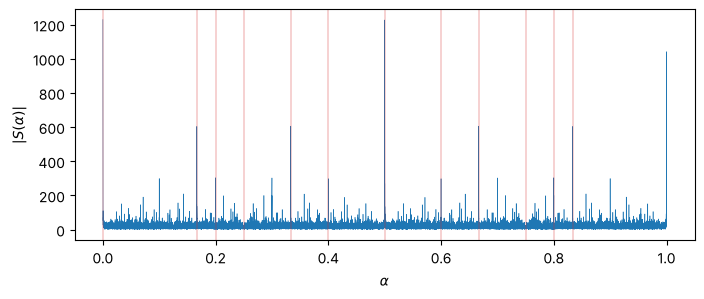

In [7]:
Nn = 10**4
K = 1 << 15
ind = np.zeros(K); ind[primes[primes <= Nn]] = 1
Sa = np.fft.ifft(ind) * K          # S(j/K) = sum_p e(p j / K)
j = np.arange(K)
print('integral of S^2 e(-N a):', np.real(np.mean(Sa**2 * np.exp(-2j * np.pi * Nn * j / K))).round(6), '  r(N) =', r[Nn])
print('integral of |S|^2:', np.mean(np.abs(Sa)**2).round(6), '  pi(N) =', int(s[:Nn + 1].sum()))
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(j / K, np.abs(Sa), lw=0.4)
for a, q in ((0, 1), (1, 2), (1, 3), (2, 3), (1, 4), (3, 4), (1, 5), (2, 5), (3, 5), (4, 5), (1, 6), (5, 6)):
    ax.axvline(a / q, color='C3', lw=0.3)
ax.set_xlabel(r'$\alpha$'); ax.set_ylabel(r'$|S(\alpha)|$'); plt.show()

Both identities hold to rounding error. The plot shows tall peaks at $\alpha=0$ and $\alpha=1$ (height $\pi(N)=1229$), at $\frac12$ (height $\pi(N)$ again, since all primes but $2$ are odd), and lower ones at $\frac13,\frac23,\frac14,\dots$, of height about $\frac{|\mu(q)|}{\varphi(q)}\pi(N)$: these are the major arcs. Everywhere else $|S|$ is much smaller, but its square still carries the $L^2$ mass $\pi(N)$ spread over the whole circle, which is the obstruction for two primes described in the chapter.